# Origin-destination analysis: worked example

This notebook walks through a full OD analysis on the Lake Tahoe street network using only the files in
this folder. It answers two questions for a set of destinations:

* **Access:** how long does it take each neighborhood to reach its destination?
* **Reliance:** which streets carry those trips, and how many people depend on each one?

It runs three examples:

1. **Evacuation, nearest exit** - every origin goes to its quickest basin exit.
2. **Medical facilities, gravity** - trips split across hospitals and clinics by travel time.
3. **Deterministic vs. stochastic** - why the analysis averages 100 routing draws.

The last section shows how to swap in your own destinations. Read `README.md` for the method and the
output fields. Runtime is about two minutes.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import odtool

DATA = Path("data")
OUT = Path("output")
pd.set_option("display.width", 160)

## 1. Inputs

* **Streets** - the Overture drivable network for the Tahoe region (`class` = road class, `name`).
* **Origins** - 2,201 hex-grid cells with `population` and `equity_wt` (1 + the block group's normalized
  poverty rate; 1.0 outside the block groups).
* **Destinations** - one GeoPackage layer per destination set.

In [2]:
streets = gpd.read_file(DATA / "tahoe_streets.gpkg")
origins = gpd.read_file(DATA / "tahoe_origins.gpkg")
print(f"{len(streets):,} street segments, {len(origins):,} origins, population {origins.population.sum():,.0f}")
import pyogrio
for layer, _ in pyogrio.list_layers(DATA / "tahoe_destinations.gpkg"):
    print(f"  destinations/{layer}: {len(gpd.read_file(DATA / 'tahoe_destinations.gpkg', layer=layer))}")
streets.groupby("class").size().sort_values(ascending=False).to_frame("segments").T

97,814 street segments, 2,201 origins, population 53,972


  destinations/evacuation_exits: 7
  destinations/law_enforcement: 7
  destinations/medical_facilities: 5


  destinations/emergency_shelters: 9
  destinations/schools: 21
  destinations/fresh_food: 33


class,service,residential,tertiary,unclassified,secondary,primary,trunk,unknown,motorway,living_street
segments,49084,29961,5884,4125,3444,2929,1102,788,449,48


## 2. Build the network

`build_network` connects lines that share an end point and gives each edge a travel time from its road
class. The speeds are starting assumptions; pass `speeds={...}` to change them, or `speed_col=` to use a
speed field on the street layer.

In [3]:
t0 = time.time()
net = odtool.build_network(streets, class_col="class")
print(f"{net.n:,} nodes, {len(net.edges):,} edges, {net.main.mean():.1%} of nodes in the main connected network "
      f"({time.time() - t0:.0f} s)")
pd.Series(odtool.SPEED_MPH, name="mph").to_frame().T

80,783 nodes, 97,814 edges, 98.4% of nodes in the main connected network (1 s)


,motorway,trunk,primary,secondary,tertiary,unclassified,residential,living_street,service,unknown
mph,55,45,35,30,30,25,25,10,10,15


## 3. Example 1: evacuation to the nearest exit

`mode="nearest"`: each origin sends all of its population to the exit it reaches fastest. Each of the 100
draws perturbs every street's travel time by about 25 percent, so routes that are nearly tied share the
load.

In [4]:
exits = gpd.read_file(DATA / "tahoe_destinations.gpkg", layer="evacuation_exits")
evac = odtool.run_od(net, origins, exits, mode="nearest", population="population",
                     weight="equity_wt", origin_id="origin_id", n_draws=100, sigma=0.25)
pd.Series(evac.summary).to_frame("evacuation").T

network 82,580 nodes / 99,611 edges; 2,201 origins, 7 destinations; median snap 33 m


100 draw(s) in 22 s


done in 22.6 s: 573,631 person-km, mean trip 10.8 min, 0 origins unreachable


,mode,cost,n_draws,sigma,beta,origins,destinations,population,population_reachable,origins_unreachable,person_km,person_hours,mean_trip_min,trip_check_max_gap,streets_routed,seconds
evacuation,nearest,time,100,0.25,None,2201,7,53972.0,53972.0,0,573630.819191,9732.487551,10.754273,0.0,9790,22.6


Trips arriving at each exit. The trip check in the summary (`trip_check_max_gap`) is the largest difference,
in any draw, between trips sent to an exit and trips that arrived there; it should be 0.

In [5]:
evac.destinations.drop(columns="geometry").round(1)

,dest_id,name,type,snap_m,trips_arriving
0,0,SR 207,evacuation exits,2.8,20454.5
1,1,SR 89,evacuation exits,0.1,56.2
2,2,US HWY 50,evacuation exits,1.9,13675.1
3,3,US HWY 50,evacuation exits,0.3,1094.6
4,4,SR 431,evacuation exits,0.9,8520.7
5,5,SR 267,evacuation exits,3.1,5408.1
6,6,SR 89,evacuation exits,16.3,4762.7


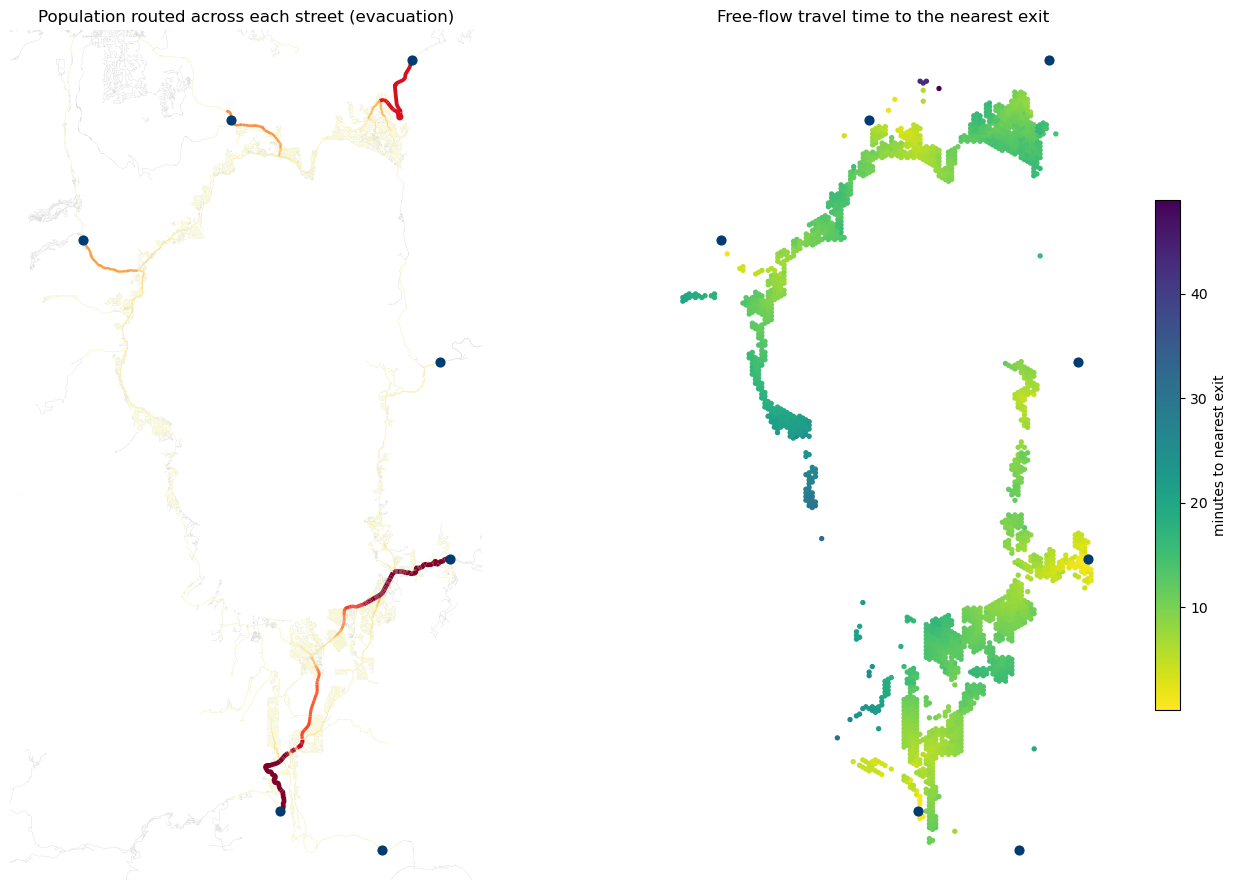

In [6]:
def traffic_map(res, title, ax, col="traffic"):
    seg = res.segments.to_crs(3310)
    seg.plot(ax=ax, color="#dddddd", linewidth=0.3)
    on = seg[seg[col] > 0]
    vmax = np.quantile(on[col], 0.99)
    on.sort_values(col).plot(ax=ax, column=col, cmap="YlOrRd", vmin=0, vmax=vmax,
                             linewidth=0.4 + 3 * np.clip(on.sort_values(col)[col] / vmax, 0, 1))
    res.destinations.to_crs(3310).plot(ax=ax, color="#003B71", markersize=40, zorder=5)
    ax.set_title(title); ax.set_axis_off()
    basin = seg[seg.in_basin == 1].total_bounds
    ax.set_xlim(basin[0] - 2000, basin[2] + 2000); ax.set_ylim(basin[1] - 2000, basin[3] + 2000)

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
traffic_map(evac, "Population routed across each street (evacuation)", axes[0])
o = evac.origins.to_crs(3310)
o[o.population > 0].plot(ax=axes[1], column="time_min", cmap="viridis_r", markersize=8, legend=True,
                         legend_kwds={"label": "minutes to nearest exit", "shrink": 0.6})
exits.to_crs(3310).plot(ax=axes[1], color="#003B71", markersize=40)
axes[1].set_xlim(axes[0].get_xlim()); axes[1].set_ylim(axes[0].get_ylim())
axes[1].set_title("Free-flow travel time to the nearest exit"); axes[1].set_axis_off()
plt.tight_layout()

The streets the most people depend on. `traffic_sd` is the draw-to-draw standard deviation: large relative
to `traffic` means the street shares its load with a near-tied alternative.

In [7]:
top = (evac.segments[evac.segments.in_basin == 1]
       .groupby(["name", "class"], dropna=True)[["traffic", "traffic_sd", "traffic_prioritarian"]].max()
       .sort_values("traffic", ascending=False).head(12).round(0))
top

,,traffic,traffic_sd,traffic_prioritarian
name,class,,,
Kingsbury Grade,primary,19796.0,5725.0,22338.0
Trooper Gary Gifford Highway,trunk,15868.0,5514.0,18167.0
Lake Tahoe Boulevard,trunk,15784.0,1696.0,18068.0
Route 50,trunk,13628.0,5255.0,15249.0
Mount Rose Highway,primary,8521.0,1396.0,8997.0
Emerald Bay Road,trunk,6484.0,1530.0,7411.0
Pioneer Trail,secondary,4894.0,874.0,5824.0
River Road,primary,4763.0,122.0,5165.0
West River Road,primary,4755.0,556.0,5157.0


## 4. Example 2: medical facilities, gravity model

`mode="gravity"`: each origin's trips split across all facilities in proportion to `time ** -beta`
(`beta = 2`), so a facility twice as far draws a quarter of the trips. The per-origin `time_min` is the
share-weighted average trip time; `od_matrix` holds every origin-to-facility time and share.

In [8]:
medical = gpd.read_file(DATA / "tahoe_destinations.gpkg", layer="medical_facilities")
med = odtool.run_od(net, origins, medical, mode="gravity", population="population",
                    weight="equity_wt", origin_id="origin_id", n_draws=100, sigma=0.25)
print({k: med.summary[k] for k in ("person_km", "person_hours", "mean_trip_min", "trip_check_max_gap", "seconds")})
med.destinations.drop(columns="geometry").round(1)

network 82,578 nodes / 99,609 edges; 2,201 origins, 5 destinations; median snap 33 m


100 draw(s) in 63 s


done in 63.4 s: 451,661 person-km, mean trip 8.9 min, 0 origins unreachable
{'person_km': 451661.1655836066, 'person_hours': 8069.406902034431, 'mean_trip_min': 8.928401815223049, 'trip_check_max_gap': 7.275957614183426e-12, 'seconds': 63.4}


,dest_id,name,type,snap_m,trips_arriving
0,0,INCLINE VILLAGE HEALTH CENTER,Hospital,16.7,9387.6
1,1,BARTON MEMORIAL HOSPITAL,Hospital,28.6,10671.0
2,2,INCLINE VILLAGE URGENT CARE,Urgent Care,2.3,7532.2
3,3,TAHOE URGENT CARE,Urgent Care,13.5,15135.3
4,4,STATELINE MEDICAL CENTER,Urgent Care,25.3,11245.9


In [9]:
# the OD matrix in long form: one row per origin x facility
med.matrix.head(10).round(3)

,origin,dest_id,dest_name,time_min,dist_km,share
0,10087,0,INCLINE VILLAGE HEALTH CENTER,64.223,67.937,0.021
1,10088,0,INCLINE VILLAGE HEALTH CENTER,64.617,67.510,0.022
2,10089,0,INCLINE VILLAGE HEALTH CENTER,64.276,67.281,0.022
3,10090,0,INCLINE VILLAGE HEALTH CENTER,64.565,67.475,0.022
4,10091,0,INCLINE VILLAGE HEALTH CENTER,64.516,67.853,0.022
5,10092,0,INCLINE VILLAGE HEALTH CENTER,63.008,66.431,0.019
6,10093,0,INCLINE VILLAGE HEALTH CENTER,63.215,66.570,0.019
7,10094,0,INCLINE VILLAGE HEALTH CENTER,63.006,66.158,0.019
8,10095,0,INCLINE VILLAGE HEALTH CENTER,62.725,66.142,0.019
9,10096,0,INCLINE VILLAGE HEALTH CENTER,62.727,66.243,0.019


## 5. Example 3: why stochastic assignment

In a street grid many routes are within a few seconds of each other. A single deterministic shortest-path
run picks one and puts every trip upstream on it, so one residential street looks critical and its
neighbors look unused. Averaging 100 perturbed draws spreads those trips across the near-ties while
leaving clearly faster roads (Lake Tahoe Blvd, collectors) carrying most of the load.

The maps compare the two for medical trips in the Al Tahoe neighborhood of South Lake Tahoe.

Text(0.5, 0.98, 'Al Tahoe: medical-facility trips on neighborhood streets')

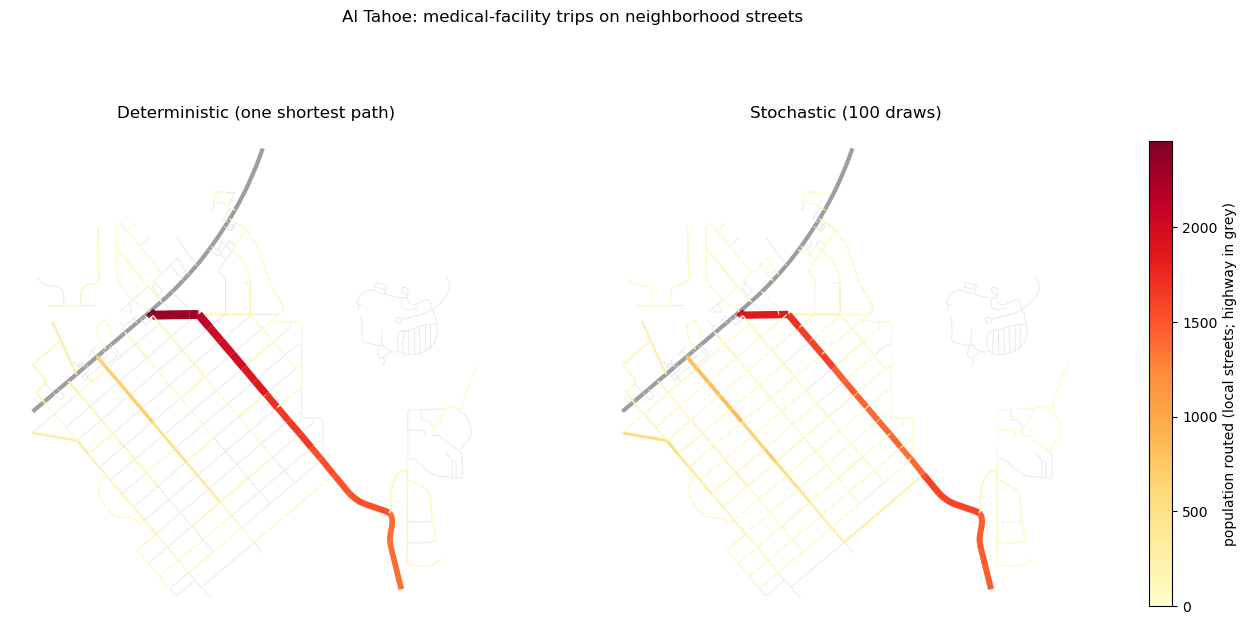

In [10]:
med_det = odtool.run_od(net, origins, medical, mode="gravity", population="population",
                        weight="equity_wt", n_draws=1, sigma=0, verbose=False)

OSBORNE = "75e2c1be-9ad1-46c9-ba33-aa9bb73931d5"     # an Osborne Ave segment in Al Tahoe
centre = streets[streets.segment_id == OSBORNE].to_crs(3310).union_all().centroid
area = centre.buffer(900)
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharex=True, sharey=True)
for ax, res, title in zip(axes, [med_det, med], ["Deterministic (one shortest path)", "Stochastic (100 draws)"]):
    seg = res.segments.to_crs(3310)
    seg = seg[seg.intersects(area)]
    art = seg["class"].isin(["motorway", "trunk", "primary"])
    seg[art].plot(ax=ax, color="#9e9e9e", linewidth=3)
    loc = seg[~art]
    vmax = float(pd.concat([med_det.segments.loc[loc.index, "traffic"], med.segments.loc[loc.index, "traffic"]]).max())
    loc.plot(ax=ax, color="#e6e6e6", linewidth=0.6)
    on = loc[loc.traffic > 0]
    on.plot(ax=ax, column="traffic", cmap="YlOrRd", vmin=0, vmax=vmax,
            linewidth=0.8 + 6 * np.clip(on.traffic / vmax, 0, 1))
    ax.set_title(title); ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(0, vmax)), ax=axes, fraction=0.02,
             label="population routed (local streets; highway in grey)")
fig.suptitle("Al Tahoe: medical-facility trips on neighborhood streets")

In [11]:
streets_near = med.segments.to_crs(3310).intersects(area)
cmp = pd.DataFrame({"name": med.segments["name"], "class": med.segments["class"],
                    "deterministic": med_det.segments.traffic, "stochastic": med.segments.traffic})[streets_near]
(cmp.dropna(subset=["name"]).groupby(["name", "class"])[["deterministic", "stochastic"]].max()
    .sort_values("stochastic", ascending=False).head(12).round(0))

,,deterministic,stochastic
name,class,,
Lake Tahoe Boulevard,trunk,11692.0,11525.0
Carson Avenue,tertiary,2455.0,2021.0
O'Malley Drive,tertiary,2304.0,1899.0
Martin Avenue,tertiary,2107.0,1707.0
Black Bart Avenue,tertiary,1371.0,1464.0
Sierra Boulevard,tertiary,692.0,845.0
Lodi Avenue,residential,343.0,569.0
River Drive,residential,336.0,538.0
Barbara Avenue,tertiary,67.0,282.0


## 6. Save outputs

`save` writes five files per analysis. The segment GeoPackage opens directly in ArcGIS Pro or QGIS; join it
to other street layers on `segment_id` (or `street_id`, the row number in `tahoe_streets.gpkg`).

In [12]:
for name, res in [("evacuation", evac), ("medical_facilities", med)]:
    res.save(OUT, name)
sorted(p.name for p in OUT.glob("*"))

['evacuation_destinations.csv',
 'evacuation_od_matrix.csv',
 'evacuation_origins.gpkg',
 'evacuation_segments.gpkg',
 'evacuation_summary.json',
 'medical_facilities_destinations.csv',
 'medical_facilities_od_matrix.csv',
 'medical_facilities_origins.gpkg',
 'medical_facilities_segments.gpkg',
 'medical_facilities_summary.json']

## 7. Your own destinations

Destinations can be any point layer (a shapefile, a GeoPackage layer, a feature class exported to GPKG, or
points built from coordinates as below). Origins work the same way: any point layer with a population
column, or `population=None` to count each origin once.

In [13]:
my_dest = gpd.GeoDataFrame(
    {"name": ["Stateline Transit Center", "Tahoe City Transit Center"]},
    geometry=gpd.points_from_xy([-119.9437, -120.1430], [38.9617, 39.1680]), crs=4326)
mine = odtool.run_od(net, origins, my_dest, mode="nearest", population="population",
                     n_draws=20, sigma=0.25)
mine.destinations.drop(columns="geometry").round(1)

network 82,574 nodes / 99,605 edges; 2,201 origins, 2 destinations; median snap 33 m


20 draw(s) in 7 s


done in 7.7 s: 624,755 person-km, mean trip 12.2 min, 0 origins unreachable


,name,snap_m,trips_arriving
0,Stateline Transit Center,28.4,35280.2
1,Tahoe City Transit Center,31.3,18691.8
